In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240220_TempoSO4_W20_run1.DSC", exp_type="francklab_esr/romana") #cooling
d2 = find_file("240220_TempoSO4_W20_run2.DSC", exp_type="francklab_esr/romana") #heating subsequently

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0$= 20 in isooctane for cooling')

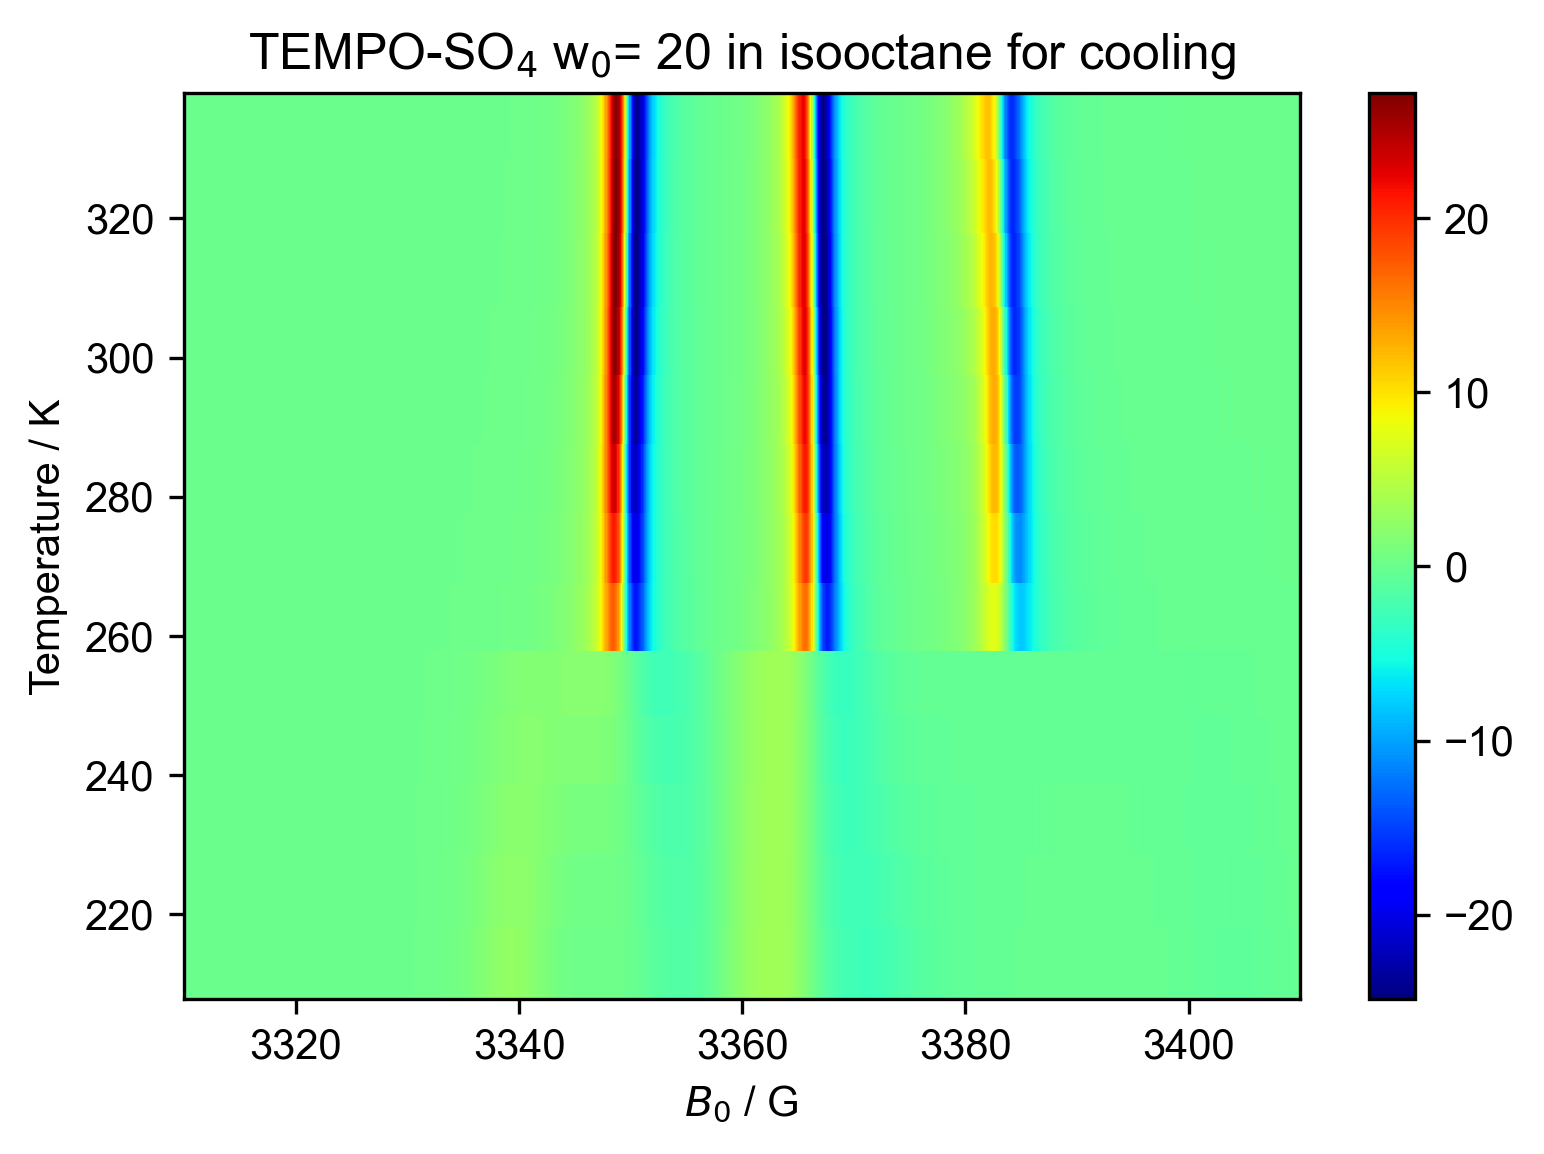

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
# d1.pcolor()
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0$= 20 in isooctane for cooling")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0$= 20 in isooctane for heating')

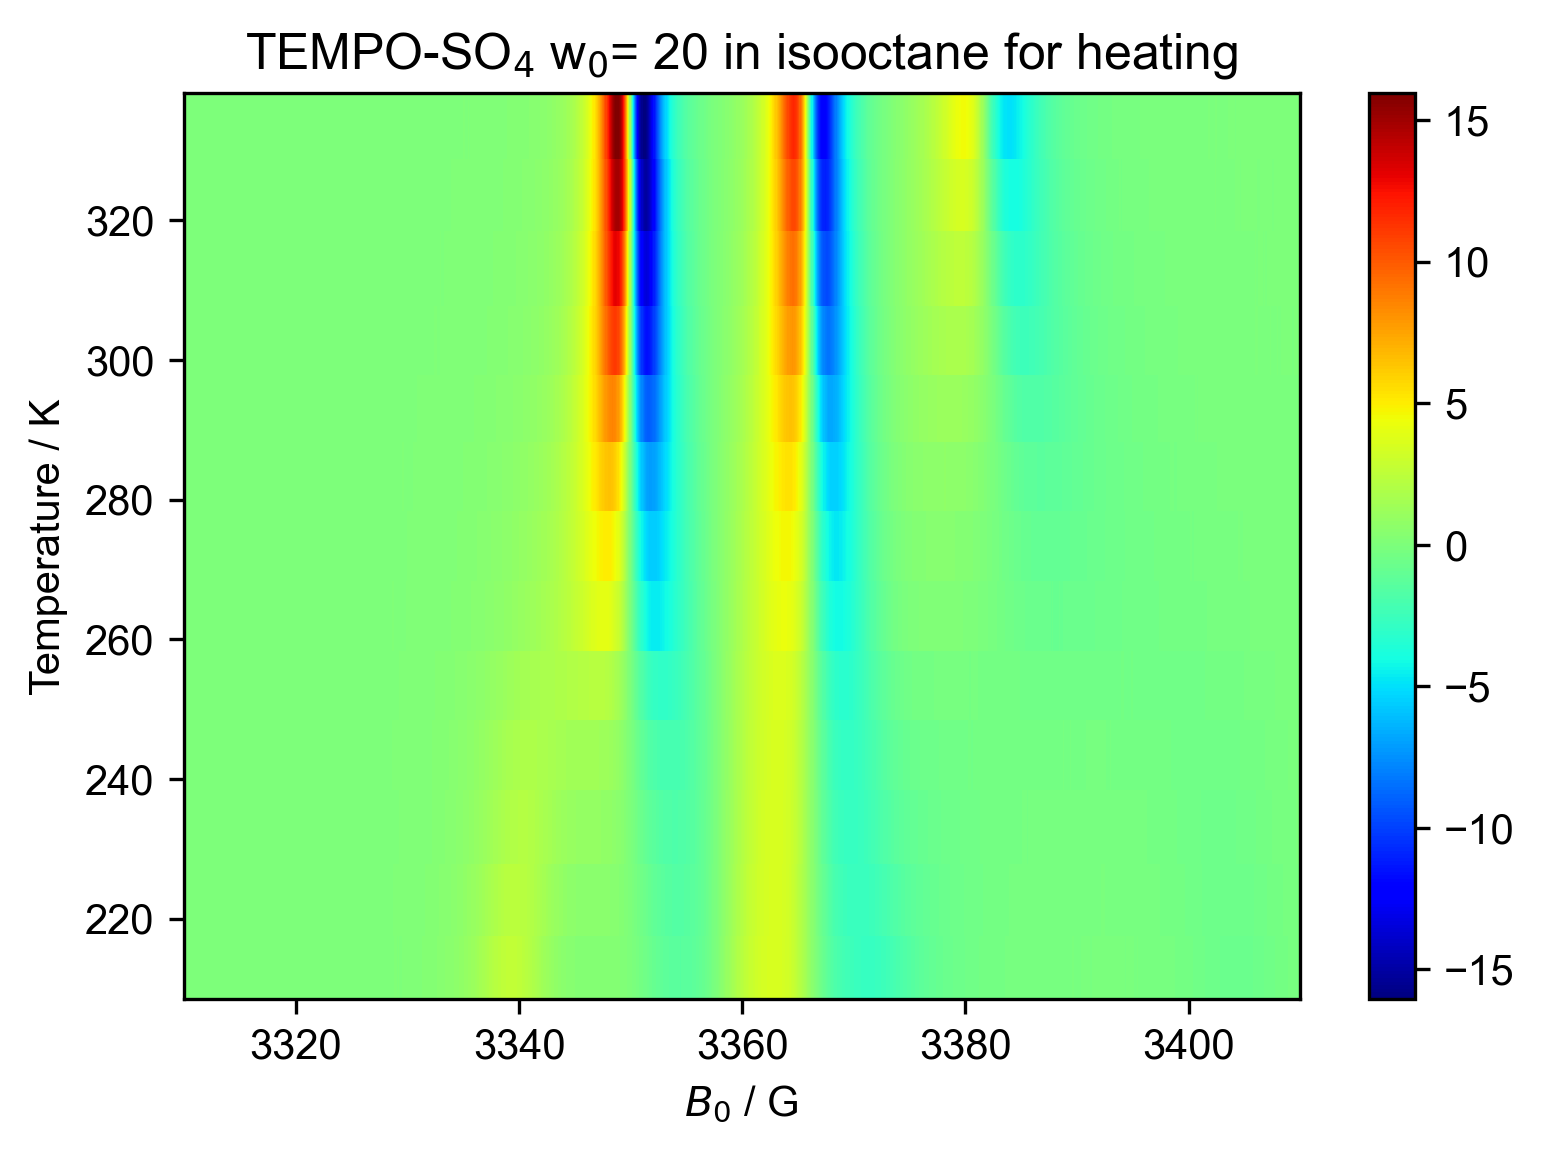

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
# d2.pcolor()
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0$= 20 in isooctane for heating")

From this, I learn that
it's easiest to show the 1D plots above and below the transition

In [9]:
# #cooling
# for this_label, temp_range in [
#     ("below transition", (None, 257.8)),
#     ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure(dpi=300) # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

In [10]:
# #cooling same plot
# for this_label, temp_range in [
#     ("All transition", (173, 373))
#  #   ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure(dpi=300) # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

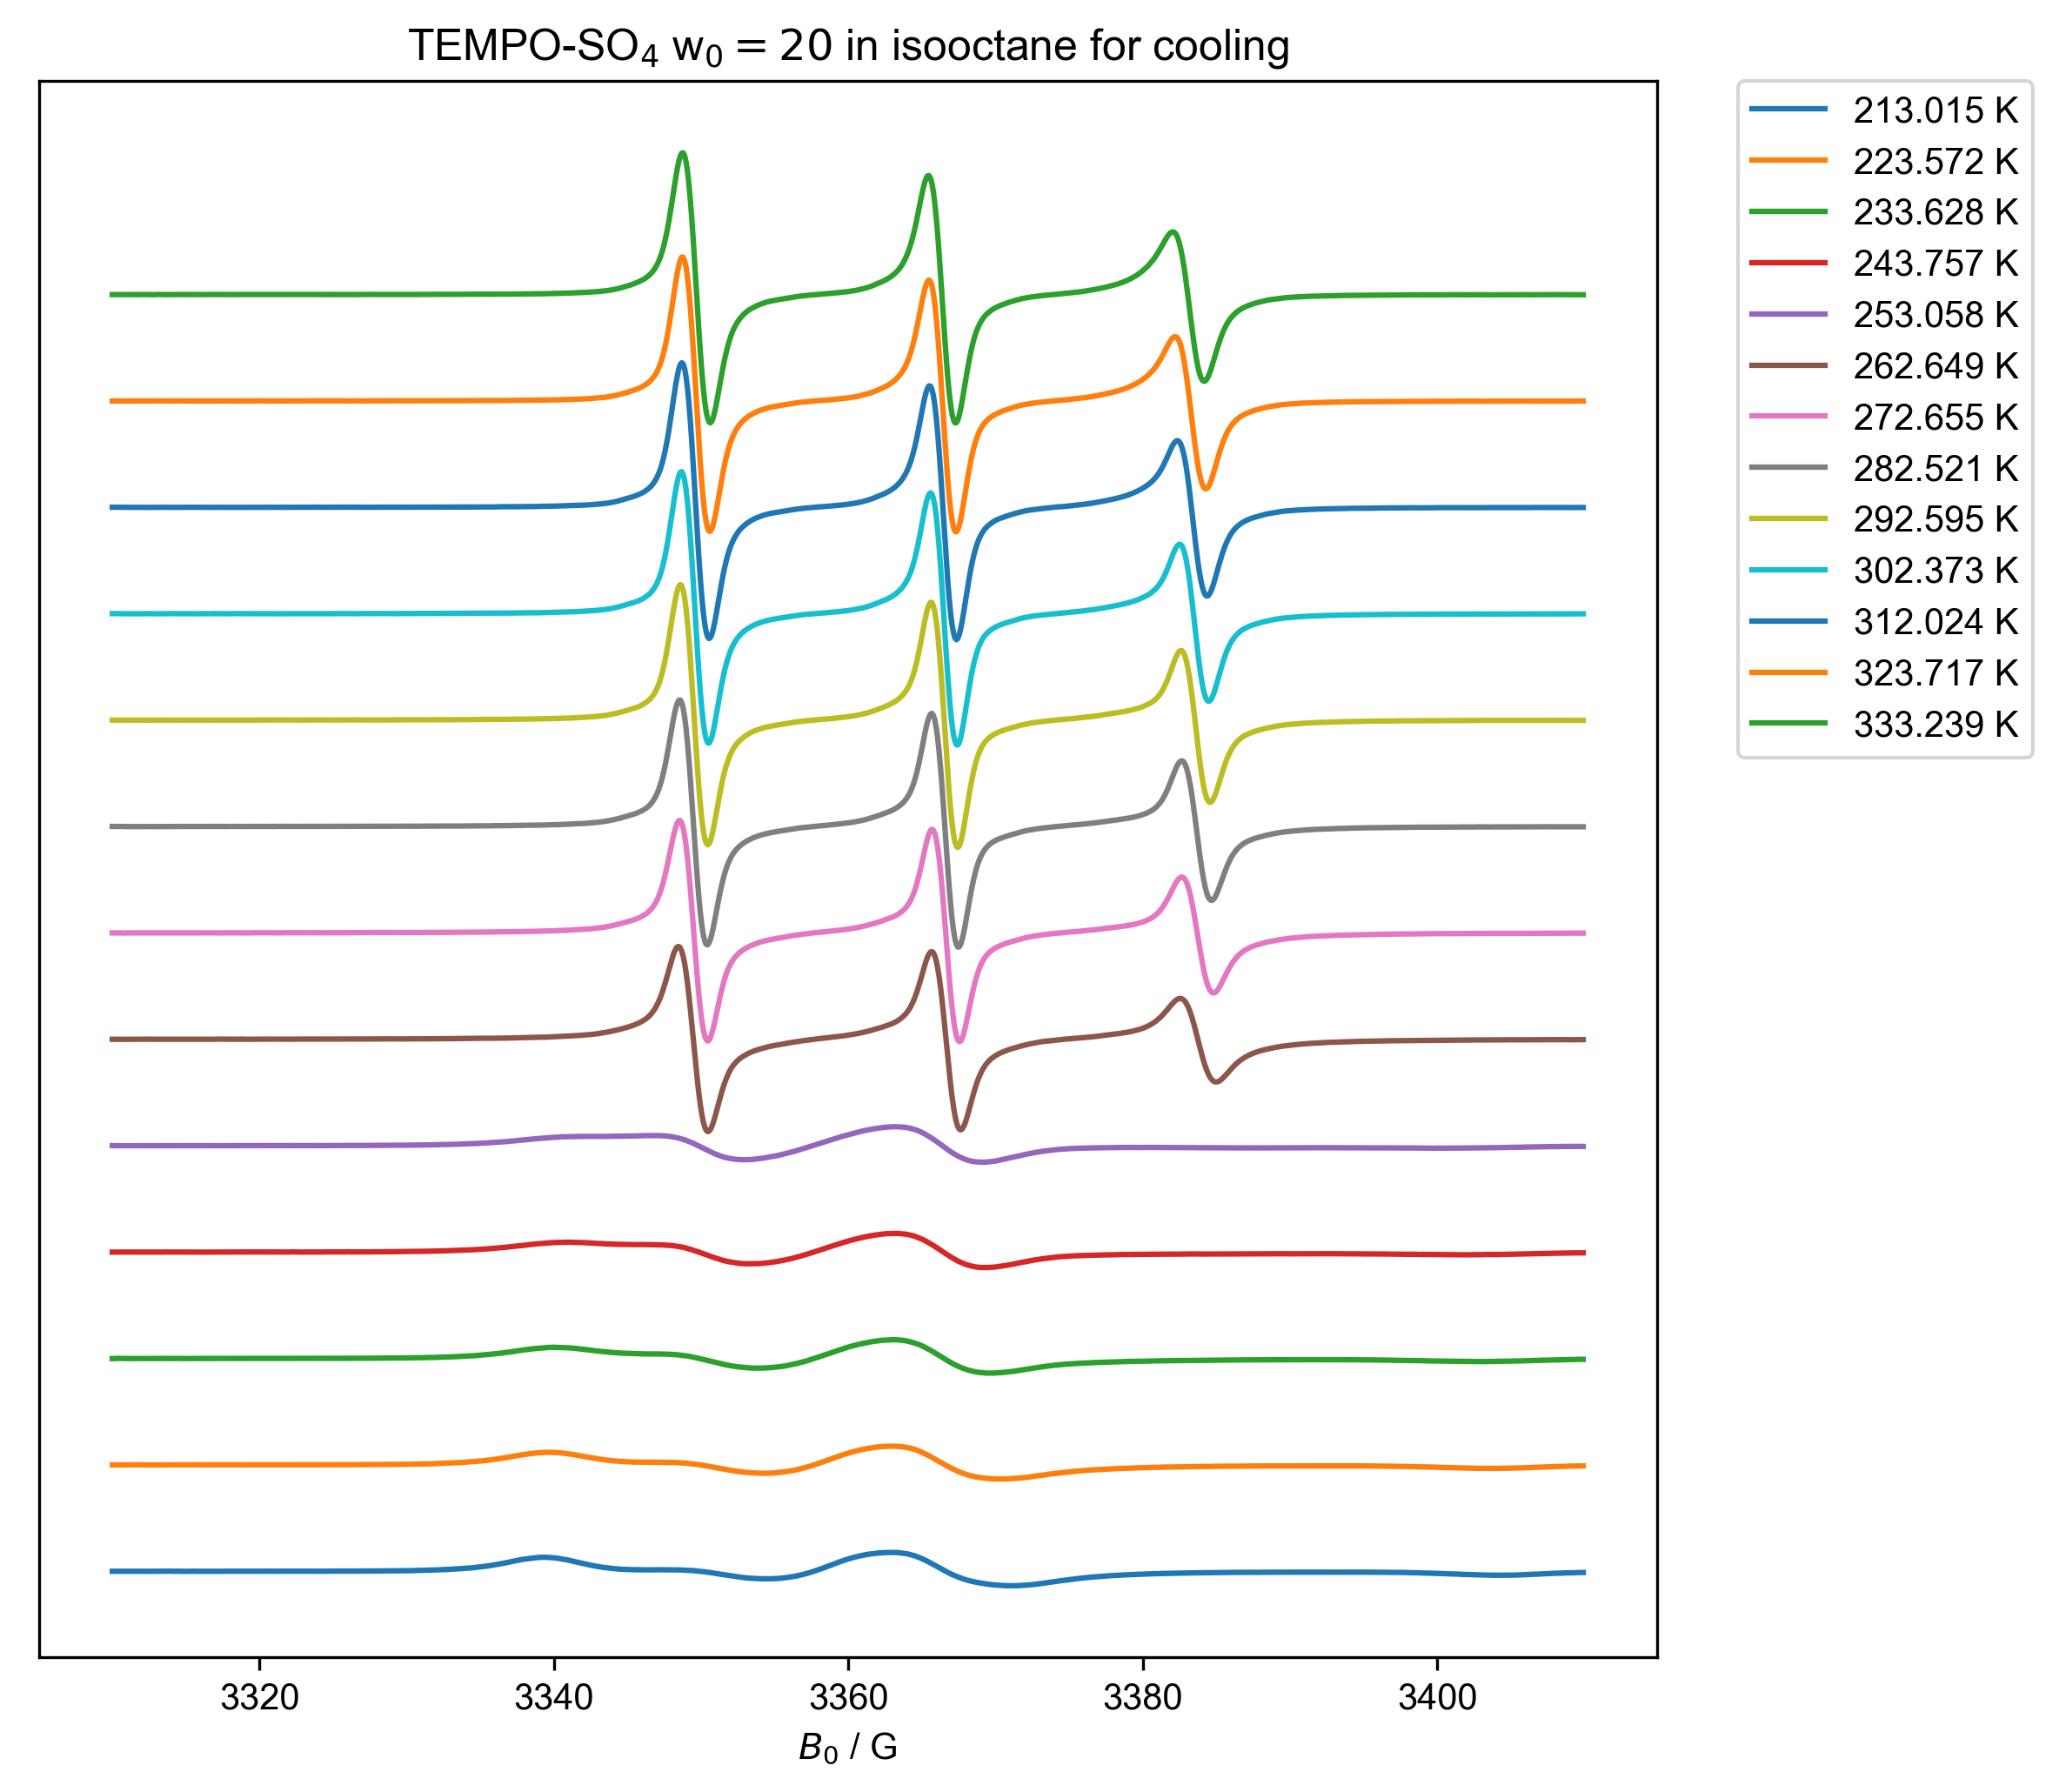

In [11]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for cooling", (173, 373))
 ]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

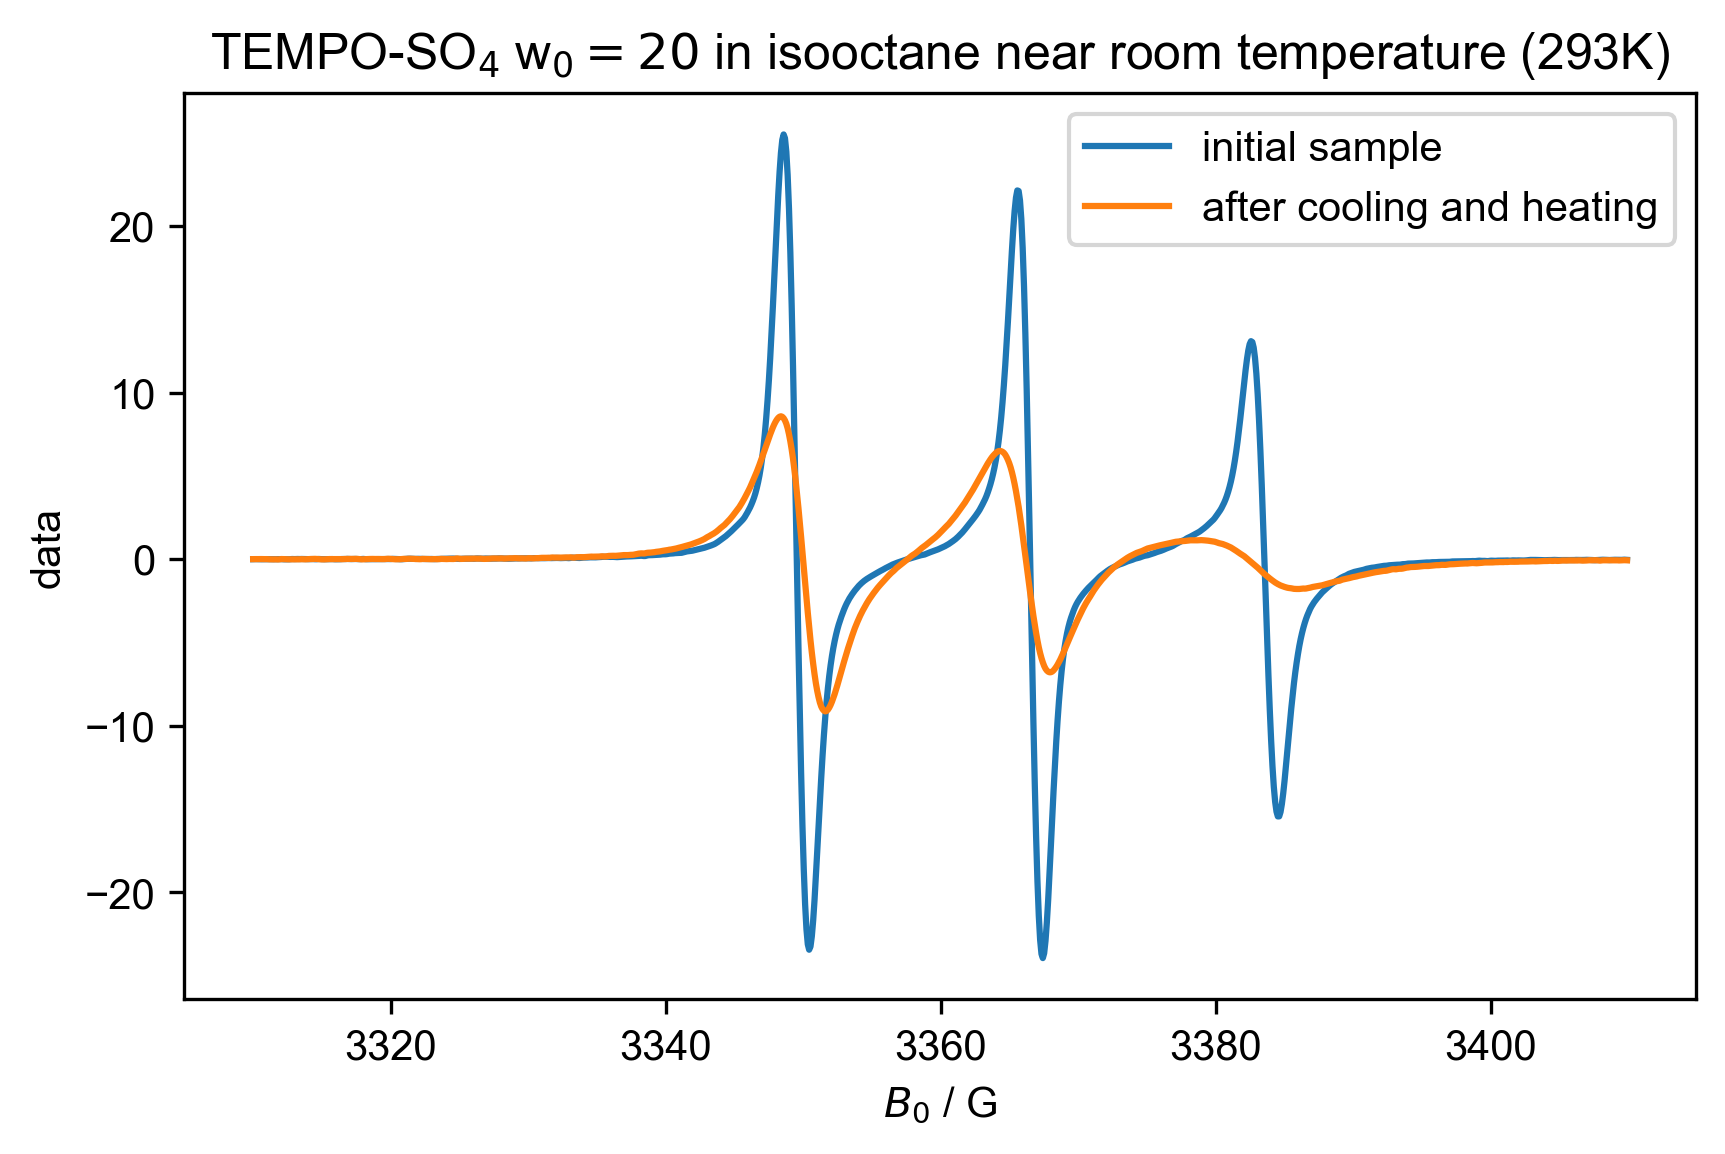

In [12]:
#near room temperature
#print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(6.5,4))
plot(d1["Temperature":292.5], label="initial sample")
plot(d2["Temperature":292.5], label="after cooling and heating")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane near room temperature (293K)")
legend()

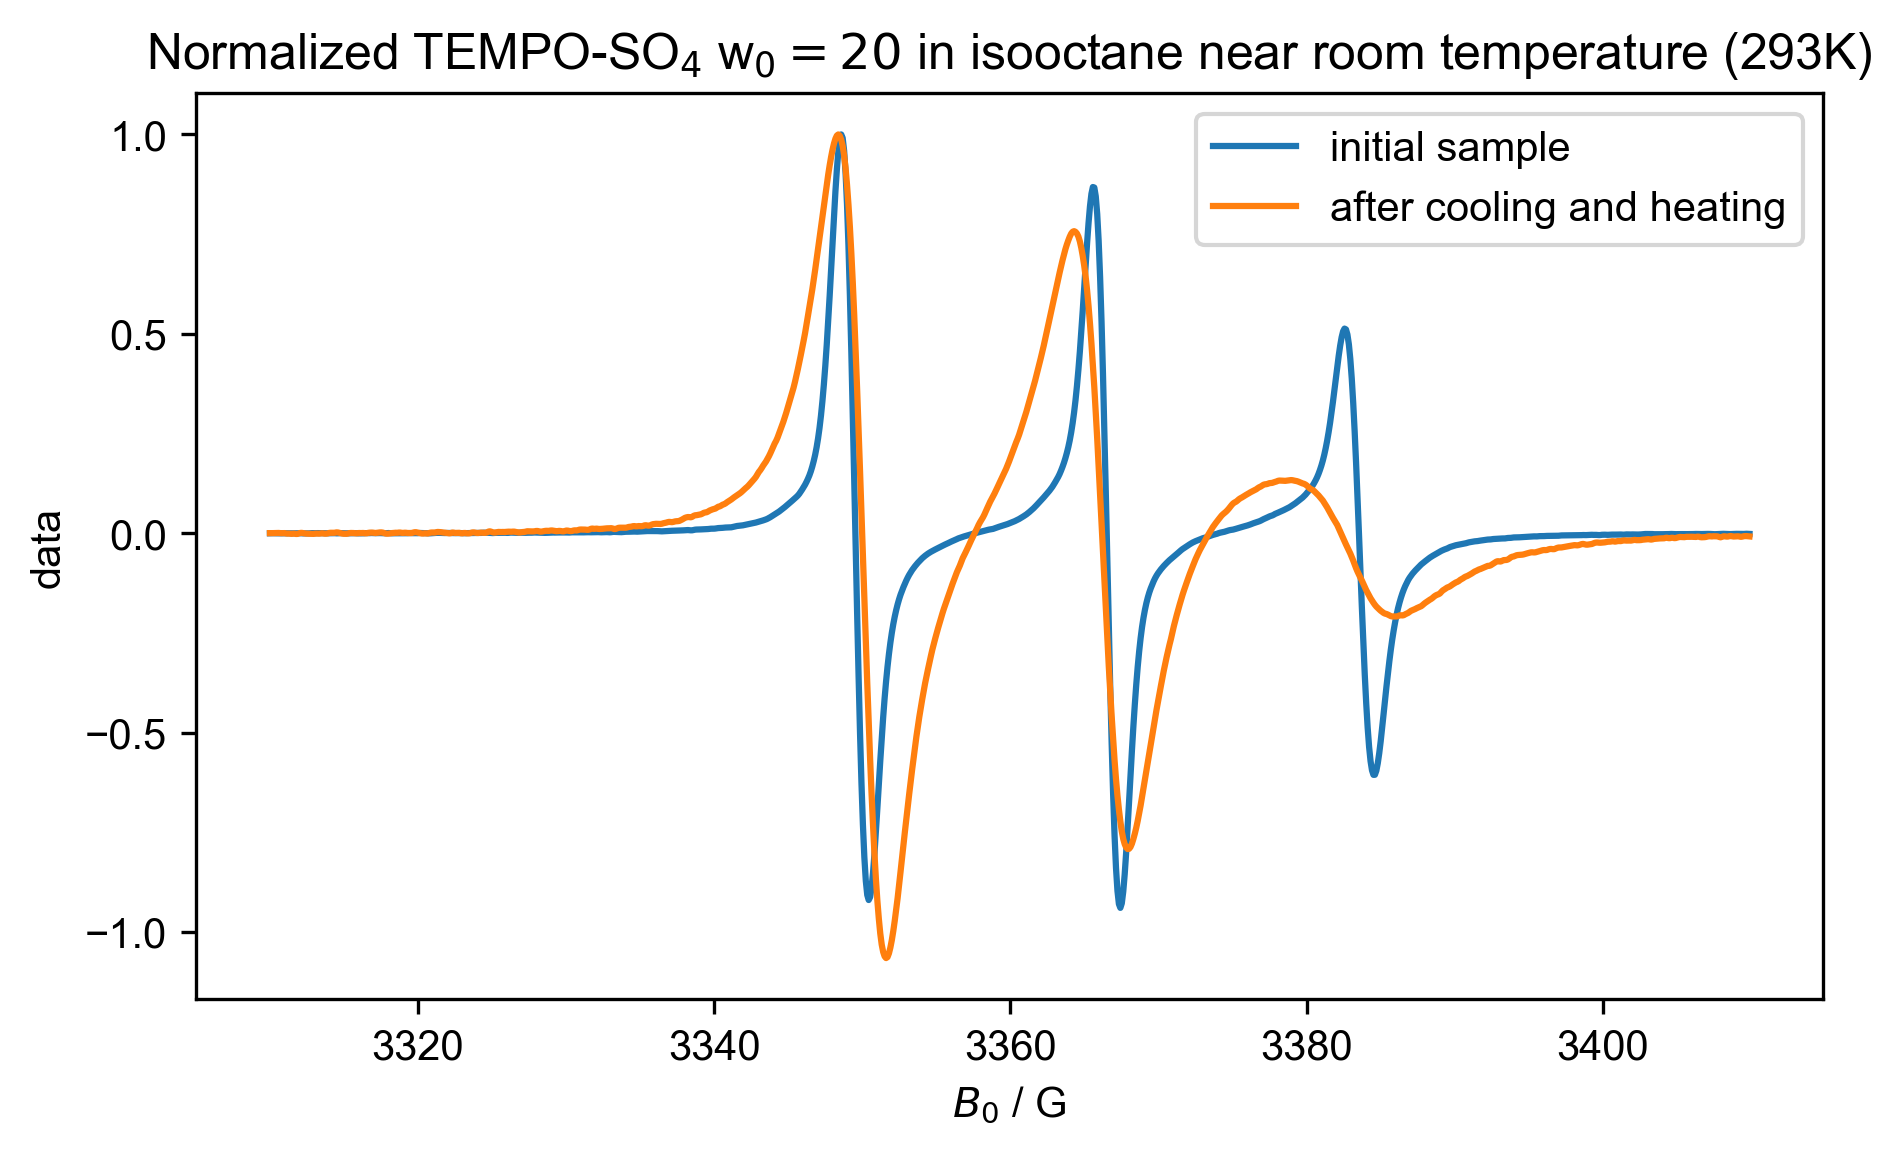

In [13]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "initial sample")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ in isooctane near room temperature (293K)")
legend()

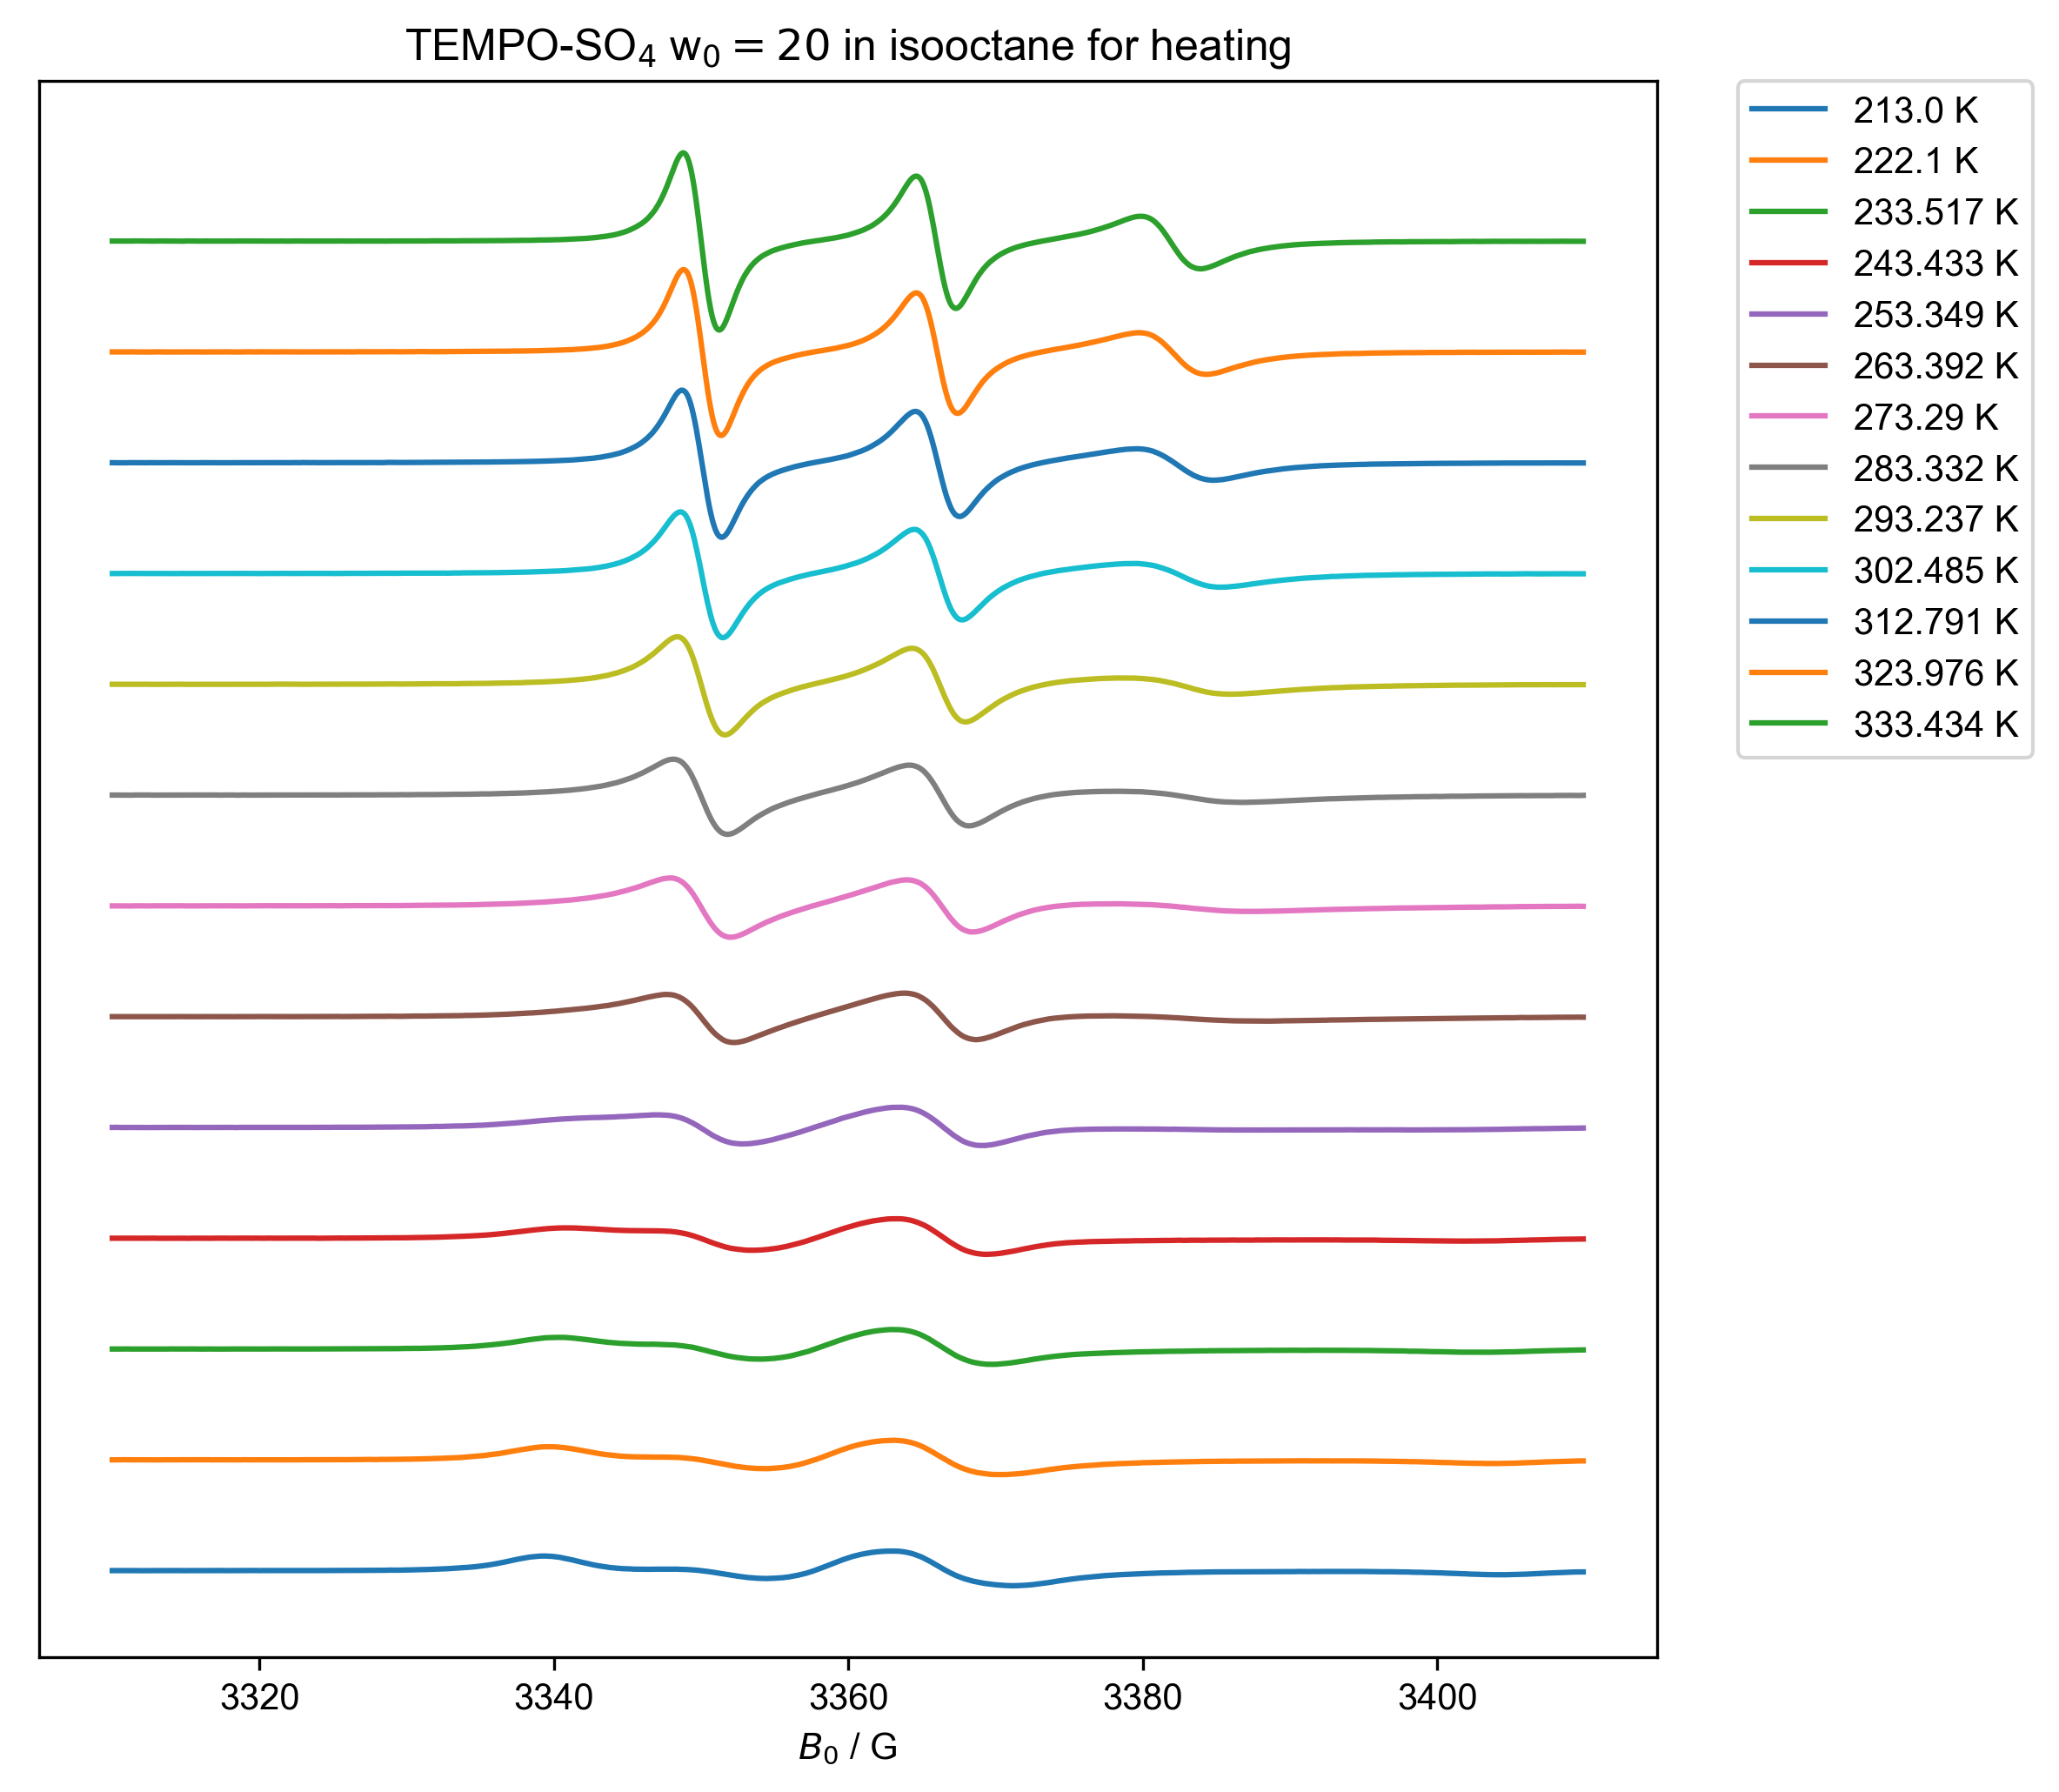

In [14]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for heating", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

In [15]:
# #heating run2
# for this_label, temp_range in [
#     ("below transition", (None, 247.8)),
#     ("above transition", (248, None)),
# ]:
#     this_d2 = d2["Temperature":temp_range]
#     figure(dpi=300) # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d2.shape["Temperature"]):
#         this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

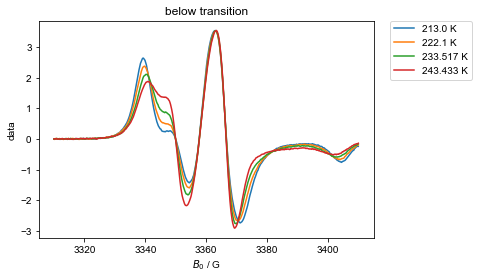

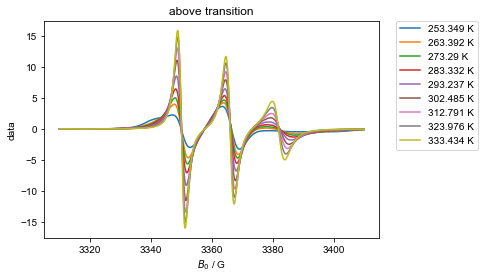

In [16]:
for this_label, temp_range in [
    ("below transition", (None, 245.8)),
    ("above transition", (253, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

What if I wanted to pull the max and min to calculate the correlation time? How would I do that?

Start by slicing out the left peak -- note that the way I loaded pyspecdata at the top, inspecting an nddata just gives me a plot:

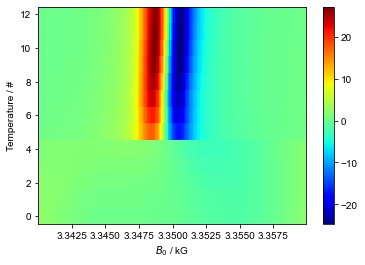

In [17]:
d1["Temperature":(213,None)]['$B_0$':(3340,3360)]

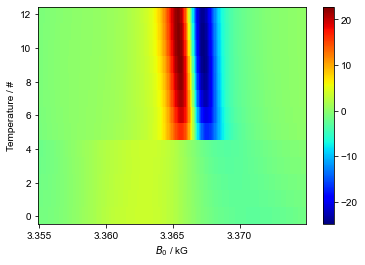

In [18]:
d1["Temperature":(213,None)]['$B_0$':(3355,3375)]

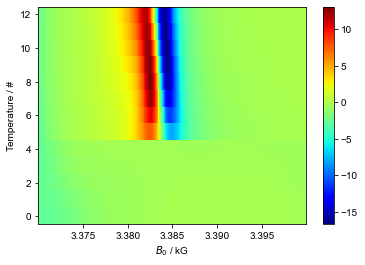

In [19]:
d1["Temperature":(213,None)]['$B_0$':(3370,3400)]

Here, I'm going to take the peak I just sliced, and determine its linewidth.  This is a simple example, but contains all the programming that I would need to, e.g. determine the correlation time or the hyperfine coupling using the traditional methods that look at the peak heights and linewidths:

the linewidth at 213.015 K is 15.429687538612143 G
the peak to peak amplitude at 213.015 K is 4.042971260103122
the linewidth at 223.572 K is 14.55078128641253 G
the peak to peak amplitude at 223.572 K is 3.9420727102494424
the linewidth at 233.628 K is 13.867187534702225 G
the peak to peak amplitude at 233.628 K is 3.9244161105595046
the linewidth at 243.757 K is 12.304687530791853 G
the peak to peak amplitude at 243.757 K is 4.064913360507247
the linewidth at 253.058 K is 5.957031264907073 G
the peak to peak amplitude at 253.058 K is 4.536878253030936
the linewidth at 262.649 K is 1.9531250048876245 G
the peak to peak amplitude at 262.649 K is 34.7920604519405
the linewidth at 272.655 K is 1.8554687546434252 G
the peak to peak amplitude at 272.655 K is 41.4452837078456
the linewidth at 282.521 K is 1.8554687546434252 G
the peak to peak amplitude at 282.521 K is 46.031043702532756
the linewidth at 292.595 K is 1.8554687546434252 G
the peak to peak amplitude at 292.595 K is 48.94489893

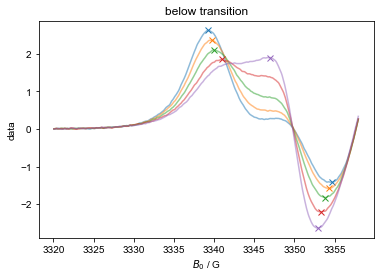

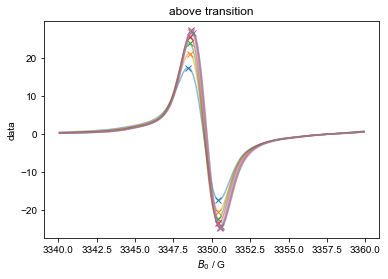

In [20]:
#Peak A
peak_amplitude_A_list =[]
for this_label, temp_range,B0_field in [
    ("below transition", (None, 260), (3320,3358)),
    ("above transition", (260, None), (3340,3360)),
]:
    this_d1 = d1["Temperature":temp_range]['$B_0$':B0_field]
    default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    peak={}
    linewidth_A_list=[]
    for j in range(this_d1.shape["Temperature"]):
        c = next(default_color_cycle)
        plot(this_d1['Temperature',j],alpha=0.5,c=c)
        field_at_max = this_d1['Temperature',j].argmax().item()
        plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
        field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
        plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
        linewidth_A = field_at_min-field_at_max
        linewidth_A_list.append(linewidth_A)
        peak_amplitude_A = this_d1['Temperature',j]['$B_0$':field_at_max].item() - this_d1['Temperature',j]['$B_0$':field_at_min].item()
        peak_amplitude_A_list.append(peak_amplitude_A)
        print("the linewidth at",this_d1['Temperature'][j],"K is",linewidth_A,"G")
        print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is", peak_amplitude_A)    
peak
print(linewidth_A_list)
print(peak_amplitude_A_list)

the linewidth at 213.015 K is 8.496093771261258 G
the peak to peak amplitude at 213.015 K is 6.267379849933807
the linewidth at 223.572 K is 7.421875018572791 G
the peak to peak amplitude at 223.572 K is 6.176471418617615
the linewidth at 233.628 K is 6.640625016617832 G
the peak to peak amplitude at 233.628 K is 6.279520935670988
the linewidth at 243.757 K is 5.7617187644182195 G
the peak to peak amplitude at 243.757 K is 6.416768466502926
the linewidth at 253.058 K is 5.957031264907073 G
the peak to peak amplitude at 253.058 K is 6.675856373240665
the linewidth at 262.649 K is 1.9531250048871698 G
the peak to peak amplitude at 262.649 K is 33.527725203804344
the linewidth at 272.655 K is 1.8554687546429705 G
the peak to peak amplitude at 272.655 K is 39.91689690809643
the linewidth at 282.521 K is 1.7578125043987711 G
the peak to peak amplitude at 282.521 K is 43.93046177362041
the linewidth at 292.595 K is 1.8554687546434252 G
the peak to peak amplitude at 292.595 K is 46.0846050071

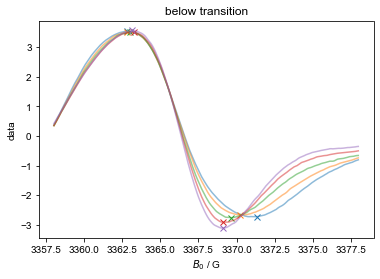

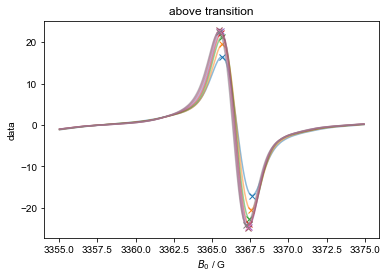

In [21]:
# Peak B
for this_label, temp_range,B0_field in [
    ("below transition", (None, 260), (3358,3378)),
    ("above transition", (260, None), (3355,3375)),
]:
    this_d1 = d1["Temperature":temp_range]['$B_0$':B0_field]
    default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    peak_amplitude_B_list =[]
    linewidth_B_list=[]
    linewidth_B_dict= []
    peak_amplitude_B_dict=[]
    for j in range(this_d1.shape["Temperature"]):
        c = next(default_color_cycle)
        plot(this_d1['Temperature',j],alpha=0.5,c=c)
        field_at_max = this_d1['Temperature',j].argmax().item()
        plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
        field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
        plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
        linewidth_B = field_at_min-field_at_max
        linewidth_B_dict.append(linewidth_B)
        peak_amplitude_B = this_d1['Temperature',j]['$B_0$':field_at_max].item() - this_d1['Temperature',j]['$B_0$':field_at_min].item()
        peak_amplitude_B_dict.append(peak_amplitude_B)
        print("the linewidth at",this_d1['Temperature'][j],"K is",linewidth_B,"G")
        print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is", peak_amplitude_B)
    linewidth_B_list.append(linewidth_B_dict)
    peak_amplitude_B_list.append(peak_amplitude_B_dict)
print(linewidth_B_list)
print(peak_amplitude_B_list)

the linewidth at 213.015 K is 12.988281282502157 G
the peak to peak amplitude at 213.015 K is 0.5895176447533446
the linewidth at 223.572 K is 10.937500027370334 G
the peak to peak amplitude at 223.572 K is 0.5034226997979376
the linewidth at 233.628 K is 12.890625032257958 G
the peak to peak amplitude at 233.628 K is 0.36899894657539023
the linewidth at 243.757 K is 9.277343773216217 G
the peak to peak amplitude at 243.757 K is 0.21811432291666666
the linewidth at 253.058 K is 20.410156301075403 G
the peak to peak amplitude at 253.058 K is 0.14756662311872915
the linewidth at 262.649 K is 2.4414062561095307 G
the peak to peak amplitude at 262.649 K is 15.685034353226033
the linewidth at 272.655 K is 2.148437505376478 G
the peak to peak amplitude at 272.655 K is 21.808741355298913
the linewidth at 282.521 K is 1.9531250048876245 G
the peak to peak amplitude at 282.521 K is 26.237009833995263
the linewidth at 292.595 K is 1.9531250048876245 G
the peak to peak amplitude at 292.595 K is 2

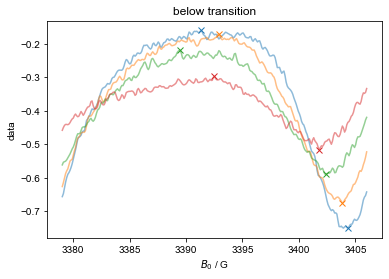

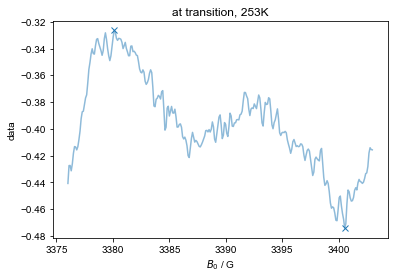

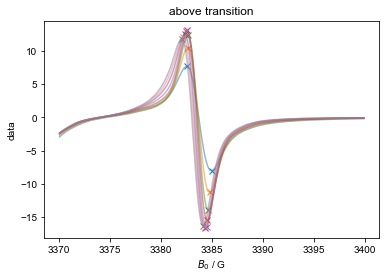

In [22]:
# Peak C
for this_label, temp_range,B0_field in [
    ("below transition", (None, 250), (3379,3406)),
    ("at transition, 253K", (250, 260), (3376,3403)),
    ("above transition", (260, None), (3370,3400)),
]:
    this_d1 = d1["Temperature":temp_range]['$B_0$':B0_field]
    default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    peak_amplitude_C_list =[]
    linewidth_C_list=[]
    peak_data={}
    for j in range(this_d1.shape["Temperature"]):
        c = next(default_color_cycle)
        plot(this_d1['Temperature',j],alpha=0.5,c=c)
        field_at_max = this_d1['Temperature',j].argmax().item()
        plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
        field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
        plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
        linewidth_C = field_at_min-field_at_max
        linewidth_C_list.append(linewidth_C) 
        peak_amplitude_C = this_d1['Temperature',j]['$B_0$':field_at_max].item() - this_d1['Temperature',j]['$B_0$':field_at_min].item()
        peak_amplitude_C_list.append(peak_amplitude_C)
        print("the linewidth at",this_d1['Temperature'][j],"K is",linewidth_C,"G")
        print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is", peak_amplitude_C)
print(linewidth_C_list)
print(peak_amplitude_C_list)
#         peak_data[linewidth_C]= linewidth_C
#         peak_data[peak_amplitude_C]= peak_amplitude_C

so that we can do math with them, let's convert the lists to numpy arrays

In [27]:
linewidth_B_list = array(linewidth_B_list)
peak_amplitude_A_list = array(peak_amplitude_A_list)
peak_amplitude_B_list = array(peak_amplitude_B_list)
tau_c = 6.51e-10*(linewidth_B_list)*(sqrt((peak_amplitude_B_list)/(peak_amplitude_A_list)
                                        )+sqrt((peak_amplitude_B_list)/(peak_amplitude_C_list))-2)
tau_c

ValueError: operands could not be broadcast together with shapes (1,8) (13,) 

In [26]:
# tau calculation
correlation_time_cooling=[]
this_d1 = d1["Temperature":(173,373)]
for j in range(this_d1.shape["Temperature"]):
    tau_c = 6.51e-10*(linewidth_B_list[j])*(sqrt((peak_amplitude_B_list[j])/(peak_amplitude_A_list[j])
                                                )+sqrt((peak_amplitude_B_list[j])/(peak_amplitude_C_list[j]))-2)
    print("correlation time at",this_d1['Temperature'][j],"K is",tau_c)
    correlation_time_cooling.append(tau_c)

correlation time at 213.015 K is [2.97752374e-09 3.30657388e-09 3.39856312e-09 3.73279496e-09
 3.82200519e-09 3.83958794e-09 3.81686290e-09 3.55999475e-09]


IndexError: index 1 is out of bounds for axis 0 with size 1

## Heating

In [ ]:
d2["Temperature":(200,None)]['$B_0$':(3340,3360)]

In [ ]:
#Peak A
this_d2 = d2["Temperature":(260,None)]['$B_0$':(3340,3360)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_A_list =[]
linewidth_A_list=[]
for j in range(this_d2.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d2['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d2['Temperature',j].argmax().item()
    plot(field_at_max,this_d2['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d2['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d2['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_A = field_at_min-field_at_max
    peak_amplitude_A = this_d2['Temperature',j]['$B_0$':field_at_max].item() - this_d2['Temperature',j]['$B_0$':field_at_min].item()
    linewidth_A_list.append(linewidth_A)
    peak_amplitude_A_list.append(peak_amplitude_A)
    print("the linewidth at",this_d2['Temperature'][j],"K is",linewidth_A,"G")
    print("the peak to peak amplitude at",this_d2['Temperature'][j],"K is", peak_amplitude_A)    

In [ ]:
d2["Temperature":(200,None)]['$B_0$':(3355,3375)]

In [ ]:
#Peak B
this_d2 = d2["Temperature":(260,None)]['$B_0$':(3355,3375)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_B_list =[]
linewidth_B_list=[]
for j in range(this_d2.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d2['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d2['Temperature',j].argmax().item()
    plot(field_at_max,this_d2['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d2['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d2['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_B = field_at_min-field_at_max
    peak_amplitude_B = this_d2['Temperature',j]['$B_0$':field_at_max].item() - this_d2['Temperature',j]['$B_0$':field_at_min].item()
    linewidth_B_list.append(linewidth_B)
    peak_amplitude_B_list.append(peak_amplitude_B)
    print("the linewidth at",this_d2['Temperature'][j],"K is",linewidth_B,"G")
    print("the peak to peak amplitude at",this_d2['Temperature'][j],"K is", peak_amplitude_B)    

In [ ]:
d2["Temperature":(200,None)]['$B_0$':(3374,3400)]

In [ ]:
#Peak C
this_d2 = d2["Temperature":(260,None)]['$B_0$':(3374,3400)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_C_list =[]
linewidth_C_list=[]
for j in range(this_d2.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d2['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d2['Temperature',j].argmax().item()
    plot(field_at_max,this_d2['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d2['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d2['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_C = field_at_min-field_at_max
    peak_amplitude_C = this_d2['Temperature',j]['$B_0$':field_at_max].item() - this_d2['Temperature',j]['$B_0$':field_at_min].item()
    linewidth_C_list.append(linewidth_C)
    peak_amplitude_C_list.append(peak_amplitude_C)
    print("the linewidth at",this_d2['Temperature'][j],"K is",linewidth_C,"G")
    print("the peak to peak amplitude at",this_d2['Temperature'][j],"K is", peak_amplitude_C)    

In [ ]:
# tau calculation
correlation_time_heating=[]
this_d2 = d2["Temperature":(260,None)]
for j in range(this_d2.shape["Temperature"]):
    tau_c = eval("6.51e-10*(linewidth_B_list[j])*(sqrt((peak_amplitude_B_list[j])/(peak_amplitude_A_list[j]))+sqrt((peak_amplitude_B_list[j])/(peak_amplitude_C_list[j]))-2)")#,{'sqrt':sqrt},peak_data)
    print("correlation time at",this_d2['Temperature'][j],"K is",tau_c)
    correlation_time_heating.append(tau_c)

In [ ]:
figure(dpi=300)
title("TEMPO-SO$_4$ in Isooctane W$_0=20$ above transition")
plot(this_d1["Temperature"],correlation_time_cooling, linestyle='-',  marker='o', label="cooling")
plot(this_d2["Temperature"],correlation_time_heating, linestyle='-', marker='o', label= "heating subsequently")
xlabel("Temperature (K)")
ylabel("Correlation time (tau)")
legend()
show()

In [ ]:
# this_d1 = d1["Temperature":(258,None)]['$B_0$':(3340,3360)]
# default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
# for j in range(this_d1.shape["Temperature"]):
#     c = next(default_color_cycle)
#     plot(this_d1['Temperature',j],alpha=0.5,c=c)
#     field_at_max = this_d1['Temperature',j].argmax().item()
#     plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
#     field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
#     plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
#     print("the linewidth at",this_d1['Temperature'][j],"K is",field_at_min-field_at_max,"G")
#     print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is",(
#         this_d1['Temperature',j]['$B_0$':field_at_max].item()
#         - this_d1['Temperature',j]['$B_0$':field_at_min].item()))